# EDA dữ liệu truy cập logistics — Task 1

Phân tích toàn bộ `data/raw_logs.txt` và `data/ip_geolocation.csv`. Các bảng, biểu đồ và nhận xét số liệu được tính từ snapshot của lần chạy; không dùng số cố định trong README.

**Cách chạy trên Windows CMD:** kích hoạt `.venv`, chạy `python -m pip install -r requirements.txt`, mở notebook bằng VS Code/Jupyter và chọn kernel `.venv/Scripts/python.exe`. Chọn **Restart Kernel → Run All**, rồi lưu notebook để cập nhật cả output và insight. Khuyến nghị có 2–3 GB RAM trống.

Notebook dùng pandas và helper của project, không khởi động Spark/Java. Dữ liệu nguồn được giữ nguyên. Biểu đồ PNG được lưu vào `data/output/eda/`. Chỉ scatter lấy mẫu có seed; mọi bảng thống kê dùng toàn bộ request thuộc nhóm phân tích.

**Câu hỏi phân tích:** Có bao nhiêu dòng/request? Lỗi thuộc loại nào? Traffic phân bố ra sao? Latency có đặc điểm gì? Kết quả HTTP 200 theo từng quốc gia có khớp helper của task 1 không? Các giới hạn của dữ liệu giả lập là gì?


## 1. Chuẩn bị môi trường

Nạp thư viện, xác định đường dẫn dữ liệu và thiết lập cách hiển thị bảng, biểu đồ. Không thay đổi file log gốc.

In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
from functools import lru_cache
from urllib.parse import urlsplit, parse_qs
import csv, hashlib, ipaddress, platform, re, sys, importlib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'helper.py').is_file() and (p / 'data').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook từ thư mục spark-core-apis hoặc thư mục con có thể tìm về project.')
LOG_PATH = ROOT / 'data/raw_logs.txt'
LOOKUP_PATH = ROOT / 'data/ip_geolocation.csv'
missing_files = [str(p) for p in [LOG_PATH, LOOKUP_PATH] if not p.is_file()]
if missing_files:
    raise FileNotFoundError('Thiếu file đầu vào: ' + ', '.join(missing_files))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import helper
helper = importlib.reload(helper)
assert Path(helper.__file__).resolve() == (ROOT / 'helper.py').resolve(), 'Kernel đang dùng helper của project khác.'
TASK_PATTERN = helper.LOG_REGEX
task_lookup = helper.load_ip_country_map(str(LOOKUP_PATH))
@lru_cache(maxsize=100000)
def task_country(ip):
    return helper.resolve_ip(ip, task_lookup)

OUT = ROOT / 'data/output/eda'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
RUN_STARTED_UTC = datetime.now(timezone.utc).isoformat()
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (11, 4.5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
def insight(text):
    display(Markdown('**Nhận xét:** ' + text))
def pct(n, d):
    return 100 * n / d if d else float('nan')
print(f'Python: {platform.python_version()} | pandas: {pd.__version__} | numpy: {np.__version__} | matplotlib: {matplotlib.__version__}')
print('Python executable:', sys.executable)
print('Project:', ROOT)
print('Bắt đầu chạy (UTC):', RUN_STARTED_UTC)


Python: 3.11.9 | pandas: 3.0.6 | numpy: 2.4.6 | matplotlib: 3.11.2
Python executable: D:\spark-core-apis\.venv\Scripts\python.exe
Project: D:\spark-core-apis
Bắt đầu chạy (UTC): 2026-10-07T16:37:45.130614+00:00


In [2]:
insight(f'Kernel hiện tại dùng Python **{platform.python_version()}**, pandas **{pd.__version__}** và đọc helper từ **{helper.__file__}**. '
        'Các nhận xét số liệu được tạo lại khi chạy; seed chỉ cố định mẫu scatter, không cố định dữ liệu do generator sinh.')


**Nhận xét:** Kernel hiện tại dùng Python **3.11.9**, pandas **3.0.6** và đọc helper từ **D:\spark-core-apis\helper.py**. Các nhận xét số liệu được tạo lại khi chạy; seed chỉ cố định mẫu scatter, không cố định dữ liệu do generator sinh.

## 2. Định nghĩa và đơn vị quan sát

| Khái niệm | Định nghĩa và cách dùng trong notebook |
|---|---|
| **Dòng vật lý** | Một dòng trong file text; có thể chứa nhiều request. |
| **Entry / request ứng viên** | Đoạn không rỗng sau khi tách dấu `;`, tương ứng đầu ra flatMap của task 1. |
| **Request được parser task chấp nhận** | Entry khớp `helper.LOG_REGEX`; regex chỉ lấy IP/status, chưa xác nhận IP/ngày hợp lệ. |
| **Request EDA hợp lệ** | Khớp định dạng đầy đủ và qua kiểm tra IPv4, timestamp có timezone, HTTP status 100–599. |
| **Entry lỗi** | Entry không qua parser EDA; gán nguyên nhân đầu tiên: định dạng → IP → timestamp → status. |
| **HTTP lỗi** | Request EDA hợp lệ có status 400–599. Khác với entry hỏng; task 1 chỉ giữ đúng status 200. |
| **CIDR / lookup** | Quy tắc mô tả một dải IP và nhãn quốc gia. Các nhãn thuộc dữ liệu giả lập, không xác nhận vị trí thực. |
| **Unknown** | Helper không tìm được quốc gia cho IP, kể cả IP không hợp lệ. Vẫn là một nhóm trong kết quả task nếu request có status 200. |
| **Request trùng** | Trùng IP, timestamp, method, URL, protocol, status, bytes và latency; đếm lượt sau lần đầu, không tự xoá. |
| **Endpoint chuẩn hoá** | Bỏ query string và thay ID manifest bằng `{id}` để gom cùng loại API. |
| **Latency / response bytes** | Độ trễ trong log tính bằng ms và kích thước phản hồi bằng byte; không phải thời gian chạy Spark. |
| **P50/P95/P99** | Các phân vị mô tả phân bố; không mặc nhiên là SLA. |
| **IQR** | Q3 − Q1; gắn cờ giá trị ngoài [Q1 − 1,5×IQR; Q3 + 1,5×IQR], không tự xoá. |
| **SHA-256 / snapshot** | Hash nhận diện nội dung file của một phiên bản dữ liệu. Hash thay đổi nghĩa là nội dung thay đổi. |
| **MiB** | 1 MiB = 1.048.576 byte; khác MB thập phân. |

**Mẫu số tỷ lệ:** dòng ghép/dòng chứa lỗi chia số dòng vật lý; entry lỗi chia số entry sau tách; HTTP lỗi chia số request EDA hợp lệ; tỷ trọng HTTP 200 của task chia tổng HTTP 200 theo helper. Không trộn các mẫu số.


## 3. Kiểm tra file đầu vào

Xem dung lượng, mã SHA-256 để nhận diện phiên bản dữ liệu và 5 dòng log đầu tiên.

In [3]:
def file_sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

manifest = pd.DataFrame([{
    'file': p.name, 'bytes': p.stat().st_size,
    'MiB': p.stat().st_size / 1024**2, 'sha256': file_sha256(p)
} for p in [LOG_PATH, LOOKUP_PATH]])
display(manifest)
with LOG_PATH.open(encoding='utf-8') as f:
    for _, line in zip(range(5), f):
        print(line.rstrip())
helper_hash_at_start = file_sha256(ROOT / 'helper.py')
print('Helper SHA-256:', helper_hash_at_start)


,file,bytes,MiB,sha256
0,raw_logs.txt,119705574,114.160,e5935fea61abd4ab1900ca30ce8ea5c8267b8d185b5ba5d6f34d012cb4c65f38
1,ip_geolocation.csv,466,0.000,110b2327c8c17a1bd1edf063089ea0279abb334ffa32b2272b60499709e0a3dd


116.206.0.24 - - [16/Sep/2026:10:00:00 +0000] "GET /api/v1/shipments/track?tx_id=TXN-50258 HTTP/1.1" 200 906 139ms
103.7.32.230 - - [16/Sep/2026:10:00:00 +0000] "GET /api/v1/shipments/track?tx_id=TXN-17003 HTTP/1.1" 200 655 51ms
151.101.0.38 - - [16/Sep/2026:10:00:00 +0000] "POST /api/v1/tracking/update?tx_id=TXN-92948 HTTP/1.1" 200 413 115ms
192.168.0.230 - - [16/Sep/2026:10:00:00 +0000] "GET /api/v1/shipments/track?tx_id=TXN-85548 HTTP/1.1" 200 3359 114ms
103.21.240.19 - - [16/Sep/2026:10:00:00 +0000] "POST /api/v1/tracking/update?tx_id=TXN-52645 HTTP/1.1" 200 2538 197ms
Helper SHA-256: cac77a24e1ec2a4cb4d1165459ed0cde4223cd55df86efa12f27a74c7e32d9c0


In [4]:
insight(f'Log có dung lượng **{LOG_PATH.stat().st_size / 1024**2:.2f} MiB**, lookup **{LOOKUP_PATH.stat().st_size:,} byte**. '
        'Lookup nhỏ phù hợp để nạp vào bộ nhớ. SHA-256 phía trên nhận diện snapshot; không so sánh các tổng đếm từ hai snapshot khác nhau như một lỗi tính toán. '
        'Các dòng mẫu chỉ mô tả định dạng, không đại diện cho tỷ lệ lỗi toàn file.')


**Nhận xét:** Log có dung lượng **114.16 MiB**, lookup **466 byte**. Lookup nhỏ phù hợp để nạp vào bộ nhớ. SHA-256 phía trên nhận diện snapshot; không so sánh các tổng đếm từ hai snapshot khác nhau như một lỗi tính toán. Các dòng mẫu chỉ mô tả định dạng, không đại diện cho tỷ lệ lỗi toàn file.

## 4. Đọc log và thống kê chất lượng

Tách các request ghép bằng dấu `;`, đọc các trường và đếm entry hợp lệ hoặc sai định dạng. Entry lỗi được thống kê riêng; file nguồn giữ nguyên.

In [5]:
FULL_PATTERN = re.compile(
    r'^(?P<ip>\S+) - - \[(?P<timestamp>[^\]]+)\] '
    r'"(?P<method>\S+) (?P<url>\S+) HTTP/(?P<protocol>\S+)" '
    r'(?P<status>\d{3}) (?P<response_bytes>\d+) (?P<latency_ms>\d+)ms$')
audit = Counter()
errors, rows, parser_examples = [], [], []
error_counts, task_country_counts, entries_per_line = Counter(), Counter(), Counter()
ip_cache, time_cache = {}, {}

def record_error(kind, line_no, position, entry):
    error_counts[kind] += 1
    if sum(e['reason'] == kind for e in errors) < 10:
        errors.append({'line_no': line_no, 'entry_position': position,
                       'reason': kind, 'raw': entry[:250]})

def parse_full_entry(entry):
    match = FULL_PATTERN.fullmatch(entry)
    if match is None:
        return None, 'invalid_format'
    d = match.groupdict()
    try:
        if d['ip'] not in ip_cache:
            ip_cache[d['ip']] = int(ipaddress.IPv4Address(d['ip']))
    except ValueError:
        return None, 'invalid_ip'
    try:
        if d['timestamp'] not in time_cache:
            time_cache[d['timestamp']] = datetime.strptime(d['timestamp'], '%d/%b/%Y:%H:%M:%S %z')
    except ValueError:
        return None, 'invalid_timestamp'
    if not 100 <= int(d['status']) <= 599:
        return None, 'invalid_http_status'
    return d, None

with LOG_PATH.open(encoding='utf-8') as source:
    for line_no, line in enumerate(source, 1):
        audit['physical_lines'] += 1
        parts = [p.strip() for p in line.split(';') if p.strip()]
        entries_per_line[len(parts)] += 1
        audit['blank_lines'] += int(not line.strip())
        audit['lines_without_entries'] += int(not parts)
        audit['compound_lines'] += int(len(parts) > 1)
        audit['entries'] += len(parts)
        line_has_error = False
        for position, entry in enumerate(parts, 1):
            tm = TASK_PATTERN.match(entry)
            audit['task_regex_valid'] += int(tm is not None)
            if tm is not None and int(tm.group(2)) == 200:
                audit['task_status_200'] += 1
                task_country_counts[task_country(tm.group(1))] += 1
            d, reason = parse_full_entry(entry)
            if bool(tm) != (reason is None):
                audit['parser_disagreements'] += 1
                if len(parser_examples) < 10:
                    parser_examples.append({'line_no': line_no, 'entry_position': position,
                        'task_accepts': bool(tm), 'eda_accepts': reason is None,
                        'eda_reason': reason, 'raw': entry[:250]})
            if reason is not None:
                record_error(reason, line_no, position, entry)
                line_has_error = True
                continue
            rows.append((line_no, position, len(parts), d['ip'], ip_cache[d['ip']],
                         d['timestamp'], d['method'], d['url'], d['protocol'], int(d['status']),
                         int(d['response_bytes']), int(d['latency_ms'])))
        audit['lines_with_invalid_entries'] += int(line_has_error)

df = pd.DataFrame.from_records(rows, columns=[
    'line_no', 'entry_position', 'entries_in_line', 'ip', 'ip_int', 'timestamp',
    'method', 'url', 'protocol', 'status', 'response_bytes', 'latency_ms'])
del rows
invalid_entries = sum(error_counts.values())
assert audit['entries'] == len(df) + invalid_entries
quality = pd.DataFrame([
    ('Physical lines', audit['physical_lines']), ('Blank lines', audit['blank_lines']),
    ('Lines without entries', audit['lines_without_entries']),
    ('Compound lines', audit['compound_lines']), ('Expanded entries', audit['entries']),
    ('Valid full records', len(df)), ('Invalid entries', invalid_entries),
    ('Lines containing invalid entries', audit['lines_with_invalid_entries']),
    ('Task regex accepted', audit['task_regex_valid']), ('Task HTTP 200', audit['task_status_200']),
    ('Parser disagreement entries', audit['parser_disagreements'])
], columns=['metric', 'count'])
display(quality)
insight(f"Có **{audit['physical_lines']:,} dòng**, **{audit['compound_lines']:,} dòng ghép**, tạo **{audit['entries']:,} entry**. "
        'Đơn vị đếm sau flatMap là entry, không còn là dòng vật lý.')
error_summary = pd.DataFrame({'reason': ['invalid_format', 'invalid_ip', 'invalid_timestamp', 'invalid_http_status']})
error_summary['count'] = error_summary.reason.map(error_counts).fillna(0).astype('int64')
error_summary['pct_all_entries'] = error_summary['count'].map(lambda n: pct(n, audit['entries']))
error_summary['pct_invalid_entries'] = error_summary['count'].map(lambda n: pct(n, invalid_entries))
display(error_summary)
insight(f'Có **{invalid_entries:,} entry lỗi**, chiếm **{pct(invalid_entries, audit["entries"]):.3f}% entry**. '
        'Mỗi entry gán loại lỗi đầu tiên theo thứ tự: định dạng → IP → timestamp → miền HTTP status; các nhóm không chồng nhau. '
        'Tỷ lệ trong nhóm lỗi là NaN khi không có lỗi. HTTP 400/404/500 vẫn là status hợp lệ về ngữ nghĩa.')
display(pd.DataFrame(errors, columns=['line_no', 'entry_position', 'reason', 'raw']))
insight('Mỗi nhóm giữ tối đa 10 ví dụ có vị trí nguồn để truy ngược. Số ví dụ không phải tổng số lỗi; xem bảng thống kê phía trên.')
display(pd.DataFrame(parser_examples, columns=['line_no', 'entry_position', 'task_accepts', 'eda_accepts', 'eda_reason', 'raw']))
insight(f'Có **{audit["parser_disagreements"]:,} entry** mà hai parser chấp nhận khác nhau. '
        'Bảng rỗng nghĩa là không có khác biệt ở snapshot này; khác biệt ở nguồn khác có thể do parser EDA kiểm tra chặt hơn.')
if df.empty:
    raise ValueError('Không có request EDA hợp lệ; xem các bảng audit phía trên trước khi phân tích tiếp.')
df['timestamp'] = pd.to_datetime(df['timestamp'].map(time_cache), utc=True)
for c in ['line_no', 'entry_position', 'entries_in_line', 'status', 'response_bytes', 'latency_ms']:
    df[c] = pd.to_numeric(df[c], downcast='unsigned')
for c in ['ip', 'method', 'protocol']:
    df[c] = df[c].astype('category')
display(df.head())
insight(f'Bảng EDA giữ **{len(df):,} request** qua kiểm tra đầy đủ. Các bản ghi bị loại vẫn còn nguyên trong file nguồn và được audit riêng.')


,metric,count
0,Physical lines,1000000
1,Blank lines,0
2,Lines without entries,0
3,Compound lines,34454
4,Expanded entries,1034454
5,Valid full records,1020534
6,Invalid entries,13920
7,Lines containing invalid entries,13920
8,Task regex accepted,1020534
9,Task HTTP 200,981032


**Nhận xét:** Có **1,000,000 dòng**, **34,454 dòng ghép**, tạo **1,034,454 entry**. Đơn vị đếm sau flatMap là entry, không còn là dòng vật lý.

,reason,count,pct_all_entries,pct_invalid_entries
0,invalid_format,13920,1.346,100.000
1,invalid_ip,0,0.000,0.000
2,invalid_timestamp,0,0.000,0.000
3,invalid_http_status,0,0.000,0.000


**Nhận xét:** Có **13,920 entry lỗi**, chiếm **1.346% entry**. Mỗi entry gán loại lỗi đầu tiên theo thứ tự: định dạng → IP → timestamp → miền HTTP status; các nhóm không chồng nhau. Tỷ lệ trong nhóm lỗi là NaN khi không có lỗi. HTTP 400/404/500 vẫn là status hợp lệ về ngữ nghĩa.

,line_no,entry_position,reason,raw
0,123,1,invalid_format,CORRUPTED_PACKET_HEADER_0x1A55_ERR
1,261,1,invalid_format,CORRUPTED_PACKET_HEADER_0x210B_ERR
2,290,1,invalid_format,CORRUPTED_PACKET_HEADER_0x178E_ERR
3,440,1,invalid_format,CORRUPTED_PACKET_HEADER_0x813_ERR
4,561,1,invalid_format,CORRUPTED_PACKET_HEADER_0xECA_ERR
5,667,1,invalid_format,CORRUPTED_PACKET_HEADER_0x2146_ERR
6,722,1,invalid_format,CORRUPTED_PACKET_HEADER_0x1B36_ERR
7,770,1,invalid_format,CORRUPTED_PACKET_HEADER_0x26A7_ERR
8,786,1,invalid_format,CORRUPTED_PACKET_HEADER_0x2051_ERR
9,959,1,invalid_format,CORRUPTED_PACKET_HEADER_0x165E_ERR


**Nhận xét:** Mỗi nhóm giữ tối đa 10 ví dụ có vị trí nguồn để truy ngược. Số ví dụ không phải tổng số lỗi; xem bảng thống kê phía trên.

,line_no,entry_position,task_accepts,eda_accepts,eda_reason,raw


**Nhận xét:** Có **0 entry** mà hai parser chấp nhận khác nhau. Bảng rỗng nghĩa là không có khác biệt ở snapshot này; khác biệt ở nguồn khác có thể do parser EDA kiểm tra chặt hơn.

,line_no,entry_position,entries_in_line,ip,ip_int,timestamp,method,url,protocol,status,response_bytes,latency_ms
0,1,1,1,116.206.0.24,1959657496,2026-09-16 10:00:00+00:00,GET,/api/v1/shipments/track?tx_id=TXN-50258,1.1,200,906,139
1,2,1,1,103.7.32.230,1728520422,2026-09-16 10:00:00+00:00,GET,/api/v1/shipments/track?tx_id=TXN-17003,1.1,200,655,51
2,3,1,1,151.101.0.38,2539978790,2026-09-16 10:00:00+00:00,POST,/api/v1/tracking/update?tx_id=TXN-92948,1.1,200,413,115
3,4,1,1,192.168.0.230,3232235750,2026-09-16 10:00:00+00:00,GET,/api/v1/shipments/track?tx_id=TXN-85548,1.1,200,3359,114
4,5,1,1,103.21.240.19,1729490963,2026-09-16 10:00:00+00:00,POST,/api/v1/tracking/update?tx_id=TXN-52645,1.1,200,2538,197


**Nhận xét:** Bảng EDA giữ **1,020,534 request** qua kiểm tra đầy đủ. Các bản ghi bị loại vẫn còn nguyên trong file nguồn và được audit riêng.

In [6]:
insight(f'Dòng chứa entry lỗi chiếm **{pct(audit["lines_with_invalid_entries"], audit["physical_lines"]):.3f}% số dòng**, '
        f'còn entry lỗi chiếm **{pct(invalid_entries, audit["entries"]):.3f}% số entry**. '
        f'Task 1 giữ **{audit["task_status_200"]:,} HTTP 200** theo regex thực tế của helper, được đếm độc lập trước các bước lọc nghiêm ngặt của EDA.')


**Nhận xét:** Dòng chứa entry lỗi chiếm **1.392% số dòng**, còn entry lỗi chiếm **1.346% số entry**. Task 1 giữ **981,032 HTTP 200** theo regex thực tế của helper, được đếm độc lập trước các bước lọc nghiêm ngặt của EDA.

## 5. Kiểm tra bảng tra quốc gia

Kiểm tra 15 quy tắc CIDR, tìm dải IP trùng/chồng lấn và tra quốc gia cho từng IP để phục vụ EDA.

In [7]:
lookup = pd.read_csv(LOOKUP_PATH)
assert {'cidr_block', 'country_code', 'country_name'} <= set(lookup.columns)
assert not lookup.isna().any().any(), 'Lookup có giá trị thiếu'
networks = [ipaddress.IPv4Network(s) for s in lookup['cidr_block']]
overlaps = [(str(a), str(b)) for i, a in enumerate(networks)
            for b in networks[i+1:] if a.overlaps(b)]
display(lookup)
insight(f'Bảng có {len(lookup)} quy tắc; CIDR biểu diễn dải địa chỉ, không phải IP đơn lẻ. Kiểm tra trùng và chồng lấn bên dưới quyết định mức độ mơ hồ của phép lookup.')
print('Rules:', len(lookup), '| Countries:', lookup.country_code.nunique(),
      '| Duplicate CIDRs:', lookup.cidr_block.duplicated().sum())
print('Overlapping rules:', overlaps)

def locate(ip):
    n = int(ipaddress.IPv4Address(ip))
    for net, row in zip(networks, lookup.itertuples(index=False)):
        if n & int(net.netmask) == int(net.network_address):
            return row.country_code, row.country_name, row.cidr_block
    return 'Unknown', 'Unknown', 'Unknown'

locations = {ip: locate(ip) for ip in df['ip'].cat.categories}
for idx, col in enumerate(['country_code', 'country', 'cidr_block']):
    df[col] = df['ip'].astype('object').map({k: v[idx] for k, v in locations.items()}).astype('category')
print(f"Unknown requests: {(df.country == 'Unknown').sum():,} / {len(df):,}")


,cidr_block,country_code,country_name
0,103.21.240.0/20,VN,Vietnam
1,103.7.32.0/19,SG,Singapore
2,192.168.0.0/16,US,United States
3,198.51.100.0/24,US,United States
4,203.0.112.0/20,JP,Japan
5,185.220.96.0/19,DE,Germany
6,51.15.0.0/16,FR,France
7,151.101.0.0/16,GB,United Kingdom
8,210.140.0.0/16,KR,South Korea
9,139.130.0.0/16,AU,Australia


**Nhận xét:** Bảng có 15 quy tắc; CIDR biểu diễn dải địa chỉ, không phải IP đơn lẻ. Kiểm tra trùng và chồng lấn bên dưới quyết định mức độ mơ hồ của phép lookup.

Rules: 15 | Countries: 14 | Duplicate CIDRs: 0
Overlapping rules: []


Unknown requests: 0 / 1,020,534


In [8]:
insight(f'Lookup có **{len(lookup)} CIDR**, **{lookup.country_code.nunique()} quốc gia**, '
        f'**{int(lookup.cidr_block.duplicated().sum())} CIDR trùng** và **{len(overlaps)} cặp chồng lấn**. '
        f'Có **{int(df.country.eq("Unknown").sum()):,}/{len(df):,} request EDA** không ánh xạ được. '
        'Độ phủ chỉ phản ánh các IP xuất hiện trong file; khi có dải trùng/chồng lấn cần xem chênh lệch helper–EDA ở phần đối soát.')


**Nhận xét:** Lookup có **15 CIDR**, **14 quốc gia**, **0 CIDR trùng** và **0 cặp chồng lấn**. Có **0/1,020,534 request EDA** không ánh xạ được. Độ phủ chỉ phản ánh các IP xuất hiện trong file; khi có dải trùng/chồng lấn cần xem chênh lệch helper–EDA ở phần đối soát.

## 6. Kiểm tra giá trị thiếu và trùng

Xem kiểu dữ liệu, số giá trị thiếu, số giá trị khác nhau, bộ nhớ và số request trùng. Không xóa bản ghi trùng.

In [9]:
schema = pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(),
                       'unique': df.nunique(), 'memory_MiB': df.memory_usage(deep=True).drop('Index') / 1024**2})
display(schema)
insight(f'Có {int(schema.missing.sum()):,} ô thiếu trong bảng đã parse. Cột URL có {df.url.nunique():,} giá trị do cả đường dẫn và query; không coi số URL này là số loại API.')
duplicate_fields = ['ip', 'timestamp', 'method', 'url', 'protocol', 'status', 'response_bytes', 'latency_ms']
duplicates = int(df.duplicated(duplicate_fields).sum())
print(f'Duplicate records beyond first occurrence: {duplicates:,} ({duplicates / len(df):.4%})')
print(f'DataFrame memory: {df.memory_usage(deep=True).sum() / 1024**2:.1f} MiB')


,dtype,missing,unique,memory_MiB
line_no,uint32,0,986080,3.893
entry_position,uint8,0,2,0.973
entries_in_line,uint8,0,2,0.973
ip,category,0,3735,2.194
ip_int,int64,0,3735,7.786
timestamp,"datetime64[us, UTC]",0,1,7.786
method,category,0,2,0.973
url,str,0,342040,93.085
protocol,category,0,1,0.973
status,uint16,0,4,1.947


**Nhận xét:** Có 0 ô thiếu trong bảng đã parse. Cột URL có 342,040 giá trị do cả đường dẫn và query; không coi số URL này là số loại API.

Duplicate records beyond first occurrence: 3 (0.0003%)


DataFrame memory: 126.4 MiB


In [10]:
insight(f'Bảng EDA có **{int(df.isna().sum().sum()):,} ô thiếu**, **{df.ip.nunique():,} IP** và **{df.url.nunique():,} URL khác nhau**. '
        f'Có **{duplicates:,} lượt trùng sau lần đầu** ({pct(duplicates, len(df)):.4f}%); giữ nguyên để đếm từng lượt xuất hiện. '
        f'Bộ nhớ DataFrame lúc kiểm tra là **{df.memory_usage(deep=True).sum() / 1024**2:.1f} MiB**. '
        'Không có giá trị thiếu trong bảng đã parse không có nghĩa file nguồn không có entry lỗi.')


**Nhận xét:** Bảng EDA có **0 ô thiếu**, **3,735 IP** và **342,040 URL khác nhau**. Có **3 lượt trùng sau lần đầu** (0.0003%); giữ nguyên để đếm từng lượt xuất hiện. Bộ nhớ DataFrame lúc kiểm tra là **126.4 MiB**. Không có giá trị thiếu trong bảng đã parse không có nghĩa file nguồn không có entry lỗi.

## 7. Phân tích HTTP status và endpoint

Gom URL theo loại API, thống kê số request, tỷ lệ HTTP error và vẽ phân bố status/endpoint trên toàn bộ request hợp lệ.

,requests,share_pct
status,,
200,981032,96.129
400,9848,0.965
404,19747,1.935
500,9907,0.971


**Nhận xét:** HTTP 200 chiếm 96.13% request EDA; HTTP lỗi khác với entry không parse được.

requests  error_rate  median_ms  \
method endpoint                                                              
GET    /api/v1/shipments/track               498016       0.040     98.000   
POST   /api/v1/tracking/update               246462       0.000    105.000   
GET    /api/v1/manifests/wh-{id}-manifest     98568       0.000    105.000   
POST   /api/v1/dispatch/schedule              78739       0.000    105.000   
GET    /api/v1/customs/clearance              49447       0.000    105.000   
       /api/v1/rates/calculator               29547       0.000    105.000   
POST   /api/v1/orders/create                   9907       1.000    106.000   
       /api/v1/customs/declaration             9848       1.000    105.000   

                                           p95_ms  total_bytes  share_pct  
method endpoint                                                            
GET    /api/v1/shipments/track            190.000    997347937     48.800  
POST   /api/v1/tracking/update            191.000    521110153     24.150  
GET    /api/v1/manifests/wh-{id}-manifest 191.000    209058048      9.658  
POST   /api/v1/dispatch/schedule          191.000    166111739      7.715  
GET    /api/v1/customs/clearance          191.000    103913521      4.845  
       /api/v1/rates/calculator           191.000     62443714      2.895  
POST   /api/v1/orders/create              191.000     20833144      0.971  
       /api/v1/customs/declaration        191.000     20616289      0.965

**Nhận xét:** Hai nhóm method–endpoint đứng đầu chiếm 72.95% request. error_rate dùng thang 0–1, còn share_pct dùng thang 0–100.

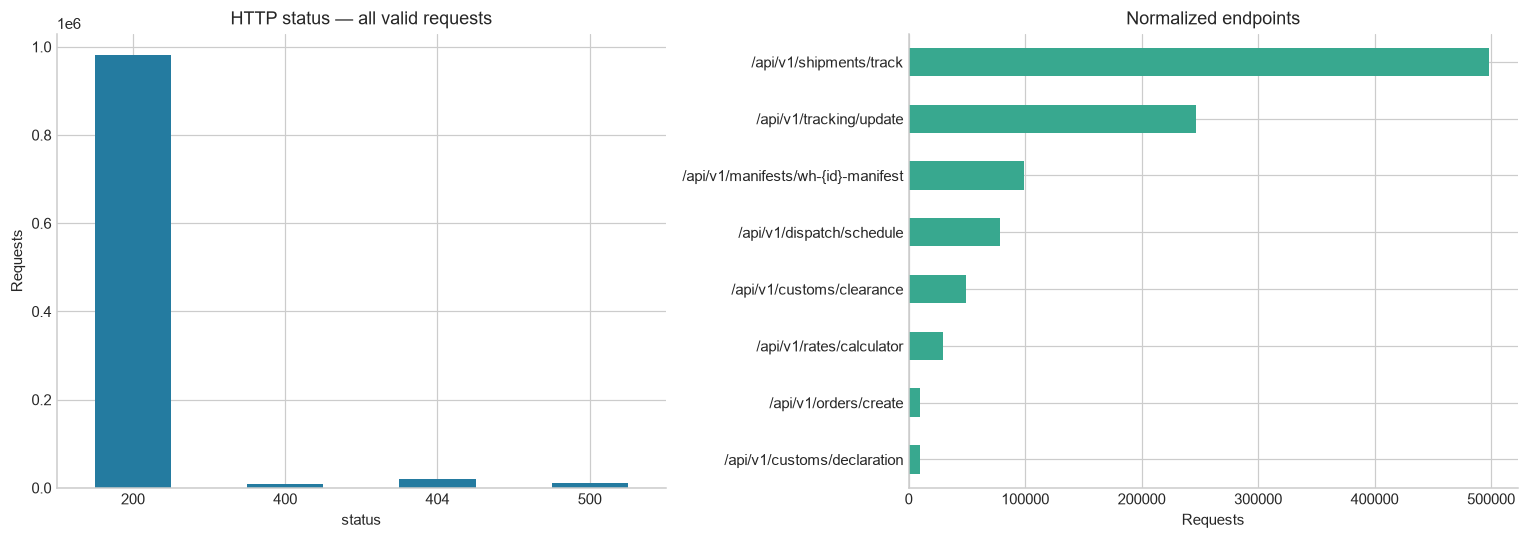

**Nhận xét:** Endpoint trên biểu đồ đã bỏ query và chuẩn hoá ID manifest. Cơ cấu traffic chịu ảnh hưởng trọng số trong generator; HTTP lỗi chiếm 3.87% request EDA.

In [11]:
def url_features(url):
    parsed = urlsplit(url)
    endpoint = re.sub(r'/wh-\d+-manifest$', '/wh-{id}-manifest', parsed.path)
    query = parse_qs(parsed.query)
    tx = query.get('tx_id', [None])[0]
    return endpoint, tx, query.get('order_id', [None])[0], query.get('entry_no', [None])[0]

url_map = {u: url_features(u) for u in df.url.unique()}
for i, column in enumerate(['endpoint', 'tx_id', 'order_id', 'entry_no']):
    df[column] = df.url.map({u: v[i] for u, v in url_map.items()})
df['endpoint'] = df.endpoint.astype('category')
df['status_class'] = (df.status.astype(int) // 100).astype(str) + 'xx'
df['http_error'] = df.status >= 400

status_summary = df.groupby('status', observed=True).agg(requests=('status', 'size'))
status_summary['share_pct'] = status_summary.requests / len(df) * 100
endpoint_summary = df.groupby(['method', 'endpoint'], observed=True).agg(
    requests=('status', 'size'), error_rate=('http_error', 'mean'),
    median_ms=('latency_ms', 'median'), p95_ms=('latency_ms', lambda s: s.quantile(.95)),
    total_bytes=('response_bytes', 'sum')).sort_values('requests', ascending=False)
endpoint_summary['share_pct'] = endpoint_summary.requests / len(df) * 100
display(status_summary)
insight(f'HTTP 200 chiếm {pct(df.status.eq(200).sum(), len(df)):.2f}% request EDA; HTTP lỗi khác với entry không parse được.')
display(endpoint_summary)
insight(f'Hai nhóm method–endpoint đứng đầu chiếm {endpoint_summary.share_pct.head(2).sum():.2f}% request. error_rate dùng thang 0–1, còn share_pct dùng thang 0–100.')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
status_summary.requests.plot.bar(ax=axes[0], color='#247BA0', rot=0)
axes[0].set(title='HTTP status — all valid requests', ylabel='Requests')
df.endpoint.value_counts().sort_values().plot.barh(ax=axes[1], color='#38A88F')
axes[1].set(title='Normalized endpoints', xlabel='Requests', ylabel='')
fig.tight_layout()
fig.savefig(OUT / 'http_endpoints.png', bbox_inches='tight')
plt.show()
insight(f'Endpoint trên biểu đồ đã bỏ query và chuẩn hoá ID manifest. Cơ cấu traffic chịu ảnh hưởng trọng số trong generator; HTTP lỗi chiếm {100 * df.http_error.mean():.2f}% request EDA.')


In [12]:
insight(f'HTTP 200 có **{int(df.status.eq(200).sum()):,} request** ({pct(df.status.eq(200).sum(), len(df)):.2f}%). '
        f'HTTP 4xx/5xx chiếm **{100 * df.http_error.mean():.2f}%** request EDA. '
        f'Hai nhóm method–endpoint đứng đầu chiếm **{endpoint_summary.share_pct.head(2).sum():.2f}%** traffic. '
        f'Có **{int(endpoint_summary.error_rate.eq(1).sum())} nhóm lỗi 100%**. '
        'Generator hiện gán status 500 cho orders/create và 400 cho customs/declaration; không diễn giải thành sự cố dịch vụ thực. '
        'Trong bảng, error_rate = 1 nghĩa là 100%.')


**Nhận xét:** HTTP 200 có **981,032 request** (96.13%). HTTP 4xx/5xx chiếm **3.87%** request EDA. Hai nhóm method–endpoint đứng đầu chiếm **72.95%** traffic. Có **2 nhóm lỗi 100%**. Generator hiện gán status 500 cho orders/create và 400 cho customs/declaration; không diễn giải thành sự cố dịch vụ thực. Trong bảng, error_rate = 1 nghĩa là 100%.

## 8. Phân tích quốc gia và IP

Thống kê request theo quốc gia/IP; tính riêng HTTP 200 và top 10 làm số liệu tham chiếu cho Task 1.

,requests,unique_ips,error_rate,p95_ms,http_200,share_pct
country,,,,,,
United States,136036,498,0.039,191.000,130723,13.330
Australia,68428,249,0.039,190.000,65732,6.705
India,68303,249,0.038,190.000,65732,6.693
Taiwan,68140,249,0.039,191.000,65477,6.677
United Kingdom,68140,249,0.039,190.000,65471,6.677
Japan,68138,249,0.037,190.000,65613,6.677
Brazil,68133,249,0.038,191.000,65548,6.676
South Korea,68108,249,0.039,191.000,65466,6.674
Singapore,68015,249,0.038,190.000,65410,6.665


**Nhận xét:** Quốc gia đứng đầu nhóm EDA là United States với 136,036 request. Nhãn địa lý lấy từ lookup giả lập, không xác nhận vị trí thực.

,access_count
country,
United States,130723
Australia,65732
India,65732
Japan,65613
Brazil,65548
Taiwan,65477
United Kingdom,65471
South Korea,65466
Singapore,65410


**Nhận xét:** Bảng chỉ hiển thị 10 nhóm đầu trong 14 nhóm của helper. Không cộng top 10 để thay thế tổng HTTP 200 đầy đủ.

,requests,country,error_rate
ip,,,
106.51.0.141,335,India,0.048
103.7.32.124,326,Singapore,0.037
210.140.0.158,326,South Korea,0.064
103.7.32.45,325,Singapore,0.022
51.15.0.81,324,France,0.031
203.0.112.129,323,Japan,0.043
116.206.0.110,322,Taiwan,0.056
139.130.0.83,322,Australia,0.031
192.168.0.228,320,United States,0.037


**Nhận xét:** IP nhiều nhất có 335 lượt. Một IP không tương đương một người dùng; bảng top IP chưa đủ để nhận diện bot.

Top 10 IP share: 0.32%
Country max / median count: 2.00


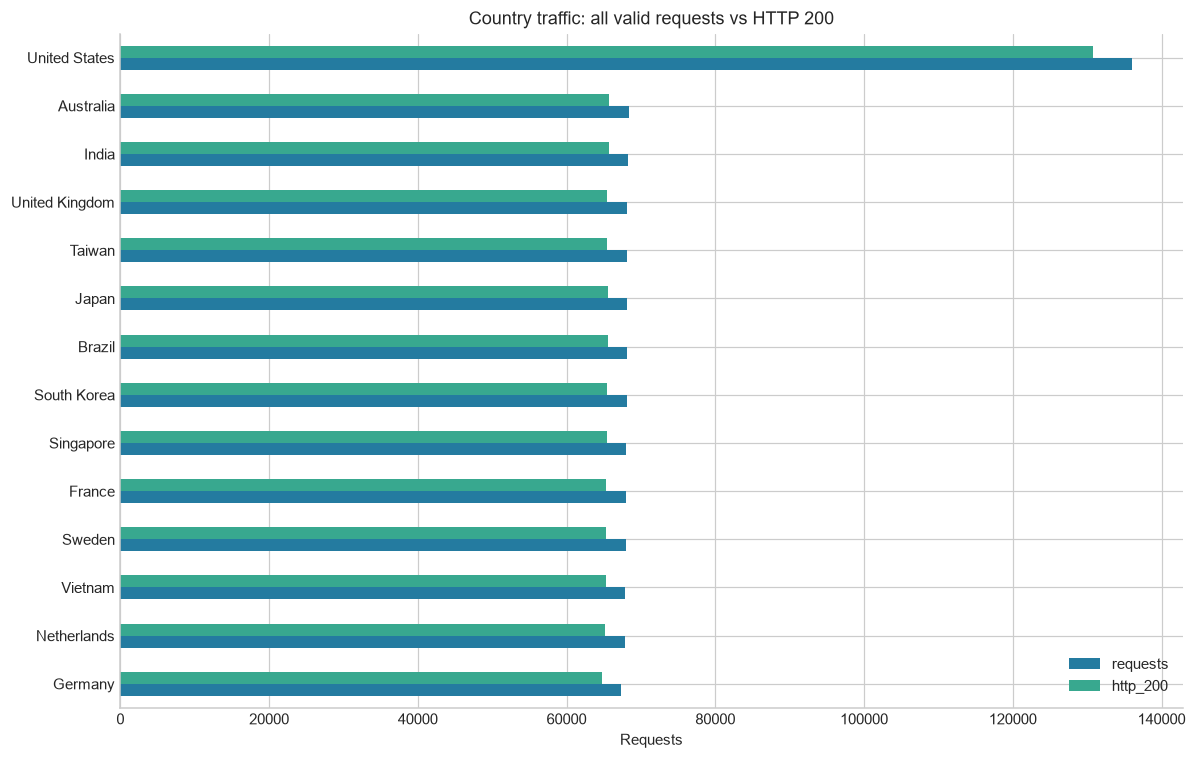

**Nhận xét:** Top 10 IP chiếm 0.32% traffic EDA. Hai cột quốc gia phân biệt mọi request EDA với HTTP 200 trong cùng tập EDA.

In [13]:
country_summary = df.groupby('country', observed=True).agg(
    requests=('status', 'size'), unique_ips=('ip', 'nunique'),
    error_rate=('http_error', 'mean'), p95_ms=('latency_ms', lambda s: s.quantile(.95)))
success_counts = df.loc[df.status == 200].groupby('country', observed=True).size()
country_summary['http_200'] = success_counts.reindex(country_summary.index, fill_value=0)
country_summary['share_pct'] = country_summary.requests / len(df) * 100
country_summary = country_summary.sort_values('requests', ascending=False)
task_reference = pd.DataFrame(task_country_counts.items(), columns=['country', 'access_count'])
task_reference = task_reference.sort_values(['access_count', 'country'], ascending=[False, True]).reset_index(drop=True)
top10_task1 = task_reference.set_index('country').head(10)
display(country_summary)
insight(f'Quốc gia đứng đầu nhóm EDA là {country_summary.index[0]} với {int(country_summary.iloc[0].requests):,} request. Nhãn địa lý lấy từ lookup giả lập, không xác nhận vị trí thực.')
display(top10_task1.rename(columns={'http_200': 'access_count'}))
insight(f'Bảng chỉ hiển thị {len(top10_task1)} nhóm đầu trong {len(task_reference)} nhóm của helper. Không cộng top 10 để thay thế tổng HTTP 200 đầy đủ.')
ip_summary = df.groupby('ip', observed=True).agg(requests=('status', 'size'),
    country=('country', 'first'), error_rate=('http_error', 'mean')).sort_values('requests', ascending=False)
display(ip_summary.head(15))
insight(f'IP nhiều nhất có {int(ip_summary.requests.max()):,} lượt. Một IP không tương đương một người dùng; bảng top IP chưa đủ để nhận diện bot.')
print(f'Top 10 IP share: {ip_summary.requests.head(10).sum() / len(df):.2%}')
print(f'Country max / median count: {country_summary.requests.max() / country_summary.requests.median():.2f}')
ax = country_summary[['requests', 'http_200']].sort_values('requests').plot.barh(figsize=(11, 7), color=['#247BA0', '#38A88F'])
ax.set(title='Country traffic: all valid requests vs HTTP 200', xlabel='Requests', ylabel='')
plt.tight_layout()
plt.savefig(OUT / 'country_traffic.png', bbox_inches='tight')
plt.show()
insight(f'Top 10 IP chiếm {pct(ip_summary.requests.head(10).sum(), len(df)):.2f}% traffic EDA. Hai cột quốc gia phân biệt mọi request EDA với HTTP 200 trong cùng tập EDA.')


In [14]:
insight(f'Quốc gia dẫn đầu traffic EDA là **{country_summary.index[0]}**, '
        f'với **{int(country_summary.iloc[0].requests):,} lượt** ({country_summary.iloc[0].share_pct:.2f}%). '
        f'Top 10 IP chiếm **{pct(ip_summary.requests.head(10).sum(), len(df)):.2f}%** request. '
        'Generator chọn pool CIDR; US có hai pool nên lợi thế số lượng có nguyên nhân từ thiết kế dữ liệu. '
        'Bảng top 10 lấy từ phép đếm bằng helper trên toàn bộ entry được task chấp nhận; biểu đồ quốc gia mô tả nhóm EDA hợp lệ. '
        'Phân bố theo IP chưa xác nhận có hay không có skew ở Spark partitions.')


**Nhận xét:** Quốc gia dẫn đầu traffic EDA là **United States**, với **136,036 lượt** (13.33%). Top 10 IP chiếm **0.32%** request. Generator chọn pool CIDR; US có hai pool nên lợi thế số lượng có nguyên nhân từ thiết kế dữ liệu. Bảng top 10 lấy từ phép đếm bằng helper trên toàn bộ entry được task chấp nhận; biểu đồ quốc gia mô tả nhóm EDA hợp lệ. Phân bố theo IP chưa xác nhận có hay không có skew ở Spark partitions.

## 9. Phân tích độ trễ và kích thước phản hồi

Tính trung bình, phân vị, giá trị ngoài ngưỡng IQR và tương quan bytes–latency. Chỉ biểu đồ scatter lấy mẫu 10.000 request; thống kê dùng toàn bộ dữ liệu hợp lệ.

,count,mean,std,min,50%,90%,95%,99%,max
response_bytes,"1,020,534.000","2,059.152","1,163.601",128.000,"2,044.000","3,689.000","3,893.000","4,055.000","4,096.000"
latency_ms,"1,020,534.000",101.968,56.558,10.000,102.000,181.000,191.000,199.000,200.000


**Nhận xét:** Latency P95/P99 là 191/199 ms. Đây là trường latency ghi trong log, không phải thời gian xử lý notebook hay Spark.

,field,lower,upper,flagged,flagged_pct
0,response_bytes,"-2,069.500","6,158.500",0,0.000
1,latency_ms,-96.500,299.500,0,0.000


**Nhận xét:** Tổng số lượt gắn cờ trên hai trường là 0; một request có thể bị gắn cờ ở cả hai trường. Ngưỡng IQR là quy tắc thống kê, không phải SLA.

,requests,median_ms,p95_ms,p99_ms
status,,,,
200,981032,101.000,191.000,199.000
400,9848,105.000,191.000,198.000
404,19747,105.000,190.000,198.000
500,9907,106.000,191.000,199.000


**Nhận xét:** So sánh theo status giúp tránh chỉ nhìn phân vị chung. Generator sinh latency trong khoảng giới hạn, nên các nhóm có thể có phân vị gần nhau mà không phản ánh dịch vụ thực.

Pearson correlation (full data): 0.07206993715736085


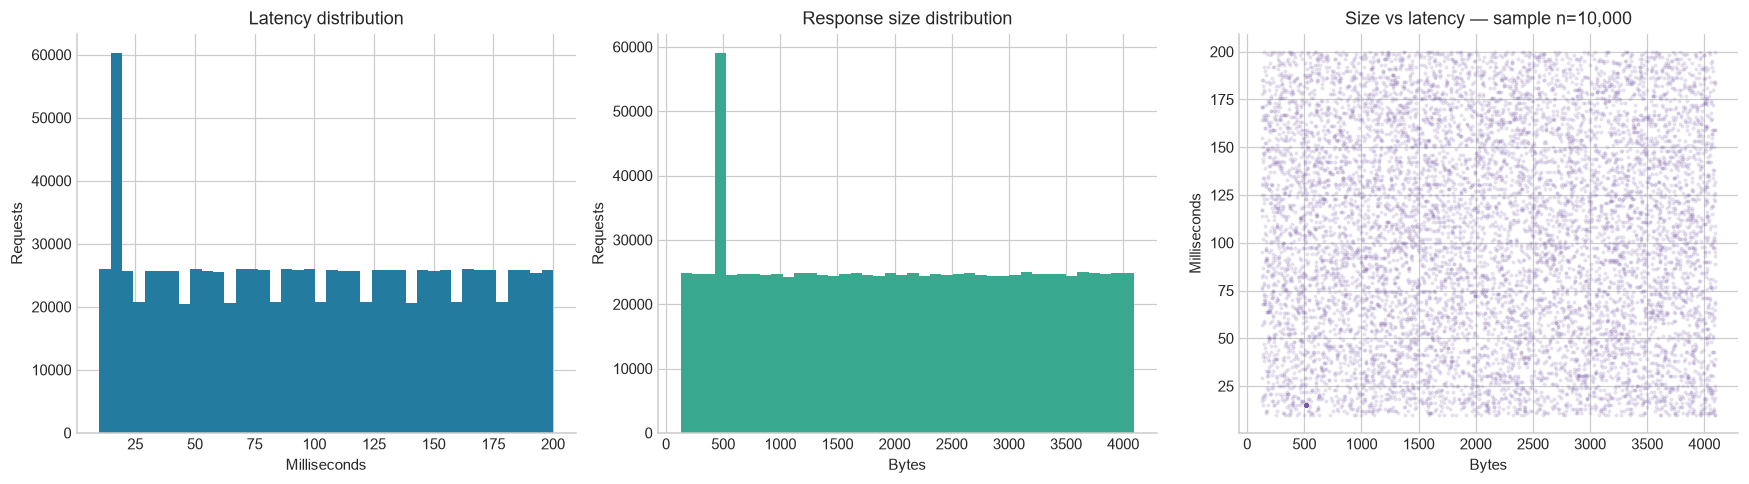

**Nhận xét:** Scatter dùng 10,000 request với seed=42. Generator đặt request phụ 15 ms và 512 byte, góp phần tạo điểm tập trung; mọi thống kê số được tính trên toàn bộ request EDA.

In [15]:
numeric_summary = df[['response_bytes', 'latency_ms']].describe(percentiles=[.5, .9, .95, .99]).T
display(numeric_summary)
insight(f'Latency P95/P99 là {df.latency_ms.quantile(.95):.0f}/{df.latency_ms.quantile(.99):.0f} ms. Đây là trường latency ghi trong log, không phải thời gian xử lý notebook hay Spark.')
outlier_rows = []
for c in ['response_bytes', 'latency_ms']:
    q1, q3 = df[c].quantile([.25, .75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    flagged = (df[c] < lo) | (df[c] > hi)
    outlier_rows.append({'field': c, 'lower': lo, 'upper': hi,
                         'flagged': int(flagged.sum()), 'flagged_pct': flagged.mean() * 100})
outliers = pd.DataFrame(outlier_rows)
display(outliers)
insight(f'Tổng số lượt gắn cờ trên hai trường là {int(outliers.flagged.sum()):,}; một request có thể bị gắn cờ ở cả hai trường. Ngưỡng IQR là quy tắc thống kê, không phải SLA.')
display(df.groupby('status').agg(requests=('status', 'size'), median_ms=('latency_ms', 'median'),
    p95_ms=('latency_ms', lambda s: s.quantile(.95)), p99_ms=('latency_ms', lambda s: s.quantile(.99))))
insight('So sánh theo status giúp tránh chỉ nhìn phân vị chung. Generator sinh latency trong khoảng giới hạn, nên các nhóm có thể có phân vị gần nhau mà không phản ánh dịch vụ thực.')
print('Pearson correlation (full data):', df.response_bytes.corr(df.latency_ms))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].hist(df.latency_ms, bins=40, color='#247BA0')
axes[0].set(title='Latency distribution', xlabel='Milliseconds', ylabel='Requests')
axes[1].hist(df.response_bytes, bins=40, color='#38A88F')
axes[1].set(title='Response size distribution', xlabel='Bytes', ylabel='Requests')
sample = df.sample(n=min(10000, len(df)), random_state=SEED)
axes[2].scatter(sample.response_bytes, sample.latency_ms, s=3, alpha=.12, color='#7659A5')
axes[2].set(title=f'Size vs latency — sample n={len(sample):,}', xlabel='Bytes', ylabel='Milliseconds')
fig.tight_layout()
fig.savefig(OUT / 'latency_size.png', bbox_inches='tight')
plt.show()
insight(f'Scatter dùng {len(sample):,} request với seed={SEED}. Generator đặt request phụ 15 ms và 512 byte, góp phần tạo điểm tập trung; mọi thống kê số được tính trên toàn bộ request EDA.')


In [16]:
insight(f'Latency trung bình **{df.latency_ms.mean():.2f} ms**, trung vị **{df.latency_ms.median():.0f} ms**, '
        f'P95/P99 **{df.latency_ms.quantile(.95):.0f}/{df.latency_ms.quantile(.99):.0f} ms**. '
        f'Bytes trung bình **{df.response_bytes.mean():.2f}**; có **{int(outliers.flagged.sum()):,} lượt gắn cờ IQR cộng trên hai trường** '
        '(một request có thể được gắn cờ ở cả hai). '
        f'Tương quan bytes–latency **{df.response_bytes.corr(df.latency_ms):.3f}**; scatter dùng **{len(sample):,} request**, còn thống kê dùng toàn bộ dữ liệu EDA. '
        'Dữ liệu sinh trong khoảng giới hạn nên không có outlier IQR cũng không chứng minh đạt SLA.')


**Nhận xét:** Latency trung bình **101.97 ms**, trung vị **102 ms**, P95/P99 **191/199 ms**. Bytes trung bình **2059.15**; có **0 lượt gắn cờ IQR cộng trên hai trường** (một request có thể được gắn cờ ở cả hai). Tương quan bytes–latency **0.072**; scatter dùng **10,000 request**, còn thống kê dùng toàn bộ dữ liệu EDA. Dữ liệu sinh trong khoảng giới hạn nên không có outlier IQR cũng không chứng minh đạt SLA.

## 10. Kiểm tra đặc điểm dữ liệu giả lập

So sánh request thứ nhất/thứ hai, kiểm tra timestamp và mức xuất hiện các mã giao dịch trong URL.

In [17]:
position_summary = df.groupby('entry_position').agg(requests=('status', 'size'),
    success_rate=('status', lambda s: (s == 200).mean()),
    median_bytes=('response_bytes', 'median'), median_ms=('latency_ms', 'median'),
    distinct_latency=('latency_ms', 'nunique'))
display(position_summary)
insight(f'Có {int(df.entry_position.gt(1).sum()):,} request phụ. So sánh theo vị trí cho thấy ảnh hưởng của phần được generator gán giá trị cố định, thay vì coi toàn bộ request là cùng một phân bố.')
print('Timestamp range:', df.timestamp.min(), '→', df.timestamp.max())
print('Unique timestamps:', df.timestamp.nunique())
if df.timestamp.nunique() <= 1:
    display(Markdown('**Không vẽ time series:** dữ liệu chỉ có một timestamp; không đủ cơ sở phân tích xu hướng.'))
else:
    df.set_index('timestamp').resample('h').size().plot(title='Requests by hour (observed timestamps)', ylabel='Requests')
    plt.tight_layout()
    plt.show()
metadata_summary = pd.DataFrame([{'field': c, 'present': df[c].notna().sum(),
    'coverage_pct': df[c].notna().mean() * 100, 'unique_values': df[c].nunique()}
    for c in ['tx_id', 'order_id', 'entry_no']])
display(metadata_summary)
insight('Độ phủ tham số có mẫu số là mọi request EDA. Các endpoint dùng query khác nhau, nên tham số không xuất hiện ở một request chưa tự chứng minh request bị lỗi.')
print('TX IDs starting with INVALID:', df.tx_id.str.startswith('INVALID-', na=False).sum())


,requests,success_rate,median_bytes,median_ms,distinct_latency
entry_position,,,,,
1,986080,0.960,"2,113.000",105.000,191
2,34454,1.000,512.000,15.000,1


**Nhận xét:** Có 34,454 request phụ. So sánh theo vị trí cho thấy ảnh hưởng của phần được generator gán giá trị cố định, thay vì coi toàn bộ request là cùng một phân bố.

Timestamp range: 2026-09-16 10:00:00+00:00 → 2026-09-16 10:00:00+00:00
Unique timestamps: 1


**Không vẽ time series:** dữ liệu chỉ có một timestamp; không đủ cơ sở phân tích xu hướng.

,field,present,coverage_pct,unique_values
0,tx_id,744478,72.950,107690
1,order_id,78739,7.715,52449
2,entry_no,49447,4.845,38097


**Nhận xét:** Độ phủ tham số có mẫu số là mọi request EDA. Các endpoint dùng query khác nhau, nên tham số không xuất hiện ở một request chưa tự chứng minh request bị lỗi.

TX IDs starting with INVALID: 19747


In [18]:
insight(f'Có **{df.timestamp.nunique():,} timestamp khác nhau**, từ **{df.timestamp.min()}** đến **{df.timestamp.max()}**. '
        + ('Chỉ một timestamp nên không suy luận xu hướng hay throughput. ' if df.timestamp.nunique() == 1 else 'Có biến thiên thời gian; cần kiểm tra độ đầy đủ của log theo kỳ. ')
        + f'Có **{int(df.entry_position.gt(1).sum()):,} request phụ**. Generator hiện đặt request thứ hai 200, 512 byte và 15 ms; bảng vị trí cho phép kiểm tra giả định này. '
        + f'Có **{int(df.tx_id.str.startswith("INVALID-", na=False).sum()):,} lượt tx_id bắt đầu INVALID-**; đây là số lượt, không phải số mã duy nhất. '
        + 'Độ phủ query parameter tính trên mọi request chỉ mô tả cơ cấu endpoint, không tự kết luận thiếu tham số bắt buộc.')


**Nhận xét:** Có **1 timestamp khác nhau**, từ **2026-09-16 10:00:00+00:00** đến **2026-09-16 10:00:00+00:00**. Chỉ một timestamp nên không suy luận xu hướng hay throughput. Có **34,454 request phụ**. Generator hiện đặt request thứ hai 200, 512 byte và 15 ms; bảng vị trí cho phép kiểm tra giả định này. Có **19,747 lượt tx_id bắt đầu INVALID-**; đây là số lượt, không phải số mã duy nhất. Độ phủ query parameter tính trên mọi request chỉ mô tả cơ cấu endpoint, không tự kết luận thiếu tham số bắt buộc.

## 11. Đối soát và tổng hợp kết quả

Kiểm tra các tổng đếm có nhất quán không, đối chiếu hai parser và tạo kết luận từ số liệu EDA. Không chạy kiểm thử phục hồi lỗi của Spark.

In [19]:
# Reference uses the actual helper on every entry accepted by the task parser.
task_series = pd.Series(task_country_counts, dtype='int64', name='helper_http_200')
eda_series = df.loc[df.status.eq(200)].groupby('country', observed=True).size().rename('eda_http_200')
country_comparison = pd.concat([task_series, eda_series], axis=1).fillna(0).astype('int64')
country_comparison['helper_minus_eda'] = country_comparison.helper_http_200 - country_comparison.eda_http_200
country_comparison = country_comparison.sort_values('helper_http_200', ascending=False)
display(country_comparison)
different_countries = int(country_comparison.helper_minus_eda.ne(0).sum())
insight(f'Có **{different_countries} nhóm quốc gia khác số đếm**. Helper đếm **{int(task_series.sum()):,} HTTP 200**, '
        f'EDA đếm **{int(eda_series.sum()):,}**. So sánh toàn bộ nhóm, gồm Unknown nếu có; không chỉ top 10. '
        'Chênh lệch cần đọc cùng bảng khác biệt parser và quy tắc CIDR, không tự loại bản ghi để làm hai bên bằng nhau.')

snapshot_checks = pd.DataFrame([{'file': p.name, 'sha256_start': manifest.set_index('file').loc[p.name, 'sha256'],
    'sha256_end': file_sha256(p)} for p in [LOG_PATH, LOOKUP_PATH]])
snapshot_checks['unchanged'] = snapshot_checks.sha256_start.eq(snapshot_checks.sha256_end)
display(snapshot_checks)
insight('Hash được tính lại khi kết thúc để phát hiện file nguồn thay đổi giữa lần chạy. '
        'Nếu có thay đổi, cần chạy lại toàn bộ notebook trên một snapshot ổn định trước khi dùng kết quả.')
checks = pd.Series({
    'Expanded entries = valid + invalid': audit['entries'] == len(df) + invalid_entries,
    'Physical lines conserved': sum(entries_per_line.values()) == audit['physical_lines'],
    'Expanded entries conserved': sum(k * v for k, v in entries_per_line.items()) == audit['entries'],
    'Country EDA counts conserved': int(country_summary.requests.sum()) == len(df),
    'HTTP status counts conserved': int(status_summary.requests.sum()) == len(df),
    'Helper country counts = task HTTP 200': int(task_series.sum()) == audit['task_status_200'],
    'EDA country HTTP 200 conserved': int(eda_series.sum()) == int(df.status.eq(200).sum()),
    'Source snapshots unchanged': bool(snapshot_checks.unchanged.all()),
    'Helper source unchanged': helper_hash_at_start == file_sha256(ROOT / 'helper.py'),
}, name='passed')
display(checks.to_frame())
insight(f'Có **{int(checks.sum())}/{len(checks)} kiểm tra bảo toàn số lượng/snapshot đạt**. '
        'Đây là kiểm tra tính nhất quán EDA; chưa chạy Spark để kiểm chứng hiệu năng, accumulator hoặc phục hồi lỗi.')
assert checks.all(), 'Có kiểm tra nội bộ không đạt; xem bảng checks trước khi sử dụng kết quả.'
parser_parity = audit['parser_disagreements'] == 0
display(pd.Series({'Same accepted entries': parser_parity,
                   'Same counts for every country': different_countries == 0}, name='parity').to_frame())
insight('Parity là kết quả chẩn đoán, không phải giả định bắt buộc: parser nghiêm ngặt có thể hợp lệ khi loại thêm entry. '
        'Nếu parity không đạt, xem ví dụ và chênh lệch từng quốc gia; bảng helper vẫn là tham chiếu theo logic task hiện tại.')


,helper_http_200,eda_http_200,helper_minus_eda
United States,130723,130723,0
India,65732,65732,0
Australia,65732,65732,0
Japan,65613,65613,0
Brazil,65548,65548,0
Taiwan,65477,65477,0
United Kingdom,65471,65471,0
South Korea,65466,65466,0
Singapore,65410,65410,0
Sweden,65345,65345,0


**Nhận xét:** Có **0 nhóm quốc gia khác số đếm**. Helper đếm **981,032 HTTP 200**, EDA đếm **981,032**. So sánh toàn bộ nhóm, gồm Unknown nếu có; không chỉ top 10. Chênh lệch cần đọc cùng bảng khác biệt parser và quy tắc CIDR, không tự loại bản ghi để làm hai bên bằng nhau.

,file,sha256_start,sha256_end,unchanged
0,raw_logs.txt,e5935fea61abd4ab1900ca30ce8ea5c8267b8d185b5ba5d6f34d012cb4c65f38,e5935fea61abd4ab1900ca30ce8ea5c8267b8d185b5ba5d6f34d012cb4c65f38,True
1,ip_geolocation.csv,110b2327c8c17a1bd1edf063089ea0279abb334ffa32b2272b60499709e0a3dd,110b2327c8c17a1bd1edf063089ea0279abb334ffa32b2272b60499709e0a3dd,True


**Nhận xét:** Hash được tính lại khi kết thúc để phát hiện file nguồn thay đổi giữa lần chạy. Nếu có thay đổi, cần chạy lại toàn bộ notebook trên một snapshot ổn định trước khi dùng kết quả.

,passed
Expanded entries = valid + invalid,True
Physical lines conserved,True
Expanded entries conserved,True
Country EDA counts conserved,True
HTTP status counts conserved,True
Helper country counts = task HTTP 200,True
EDA country HTTP 200 conserved,True
Source snapshots unchanged,True
Helper source unchanged,True


**Nhận xét:** Có **9/9 kiểm tra bảo toàn số lượng/snapshot đạt**. Đây là kiểm tra tính nhất quán EDA; chưa chạy Spark để kiểm chứng hiệu năng, accumulator hoặc phục hồi lỗi.

,parity
Same accepted entries,True
Same counts for every country,True


**Nhận xét:** Parity là kết quả chẩn đoán, không phải giả định bắt buộc: parser nghiêm ngặt có thể hợp lệ khi loại thêm entry. Nếu parity không đạt, xem ví dụ và chênh lệch từng quốc gia; bảng helper vẫn là tham chiếu theo logic task hiện tại.

In [20]:
insight(f'Snapshot hiện tại có **{audit["physical_lines"]:,} dòng → {audit["entries"]:,} entry**; '
        f'**{invalid_entries:,} entry lỗi** và **{len(df):,} request EDA hợp lệ**. '
        f'Task 1 giữ **{audit["task_status_200"]:,} HTTP 200** trên **{len(task_series)} nhóm quốc gia**; '
        f'**{different_countries} nhóm** khác kết quả EDA. '
        f'Có **{df.ip.nunique():,} IP**, **{duplicates:,} lượt trùng sau lần đầu**, **{df.timestamp.nunique()} timestamp**. '
        'Dataset phục vụ minh hoạ parsing, flatMap, lọc status và broadcast lookup. '
        'Không suy luận SLA, nhu cầu thị trường hay định vị IP thực tế từ các phân bố do generator thiết kế.')


**Nhận xét:** Snapshot hiện tại có **1,000,000 dòng → 1,034,454 entry**; **13,920 entry lỗi** và **1,020,534 request EDA hợp lệ**. Task 1 giữ **981,032 HTTP 200** trên **14 nhóm quốc gia**; **0 nhóm** khác kết quả EDA. Có **3,735 IP**, **3 lượt trùng sau lần đầu**, **1 timestamp**. Dataset phục vụ minh hoạ parsing, flatMap, lọc status và broadcast lookup. Không suy luận SLA, nhu cầu thị trường hay định vị IP thực tế từ các phân bố do generator thiết kế.